In [47]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils import data
import numpy as np
import matplotlib.pyplot as plt
import torchvision
from torchvision import transforms
from PIL import Image

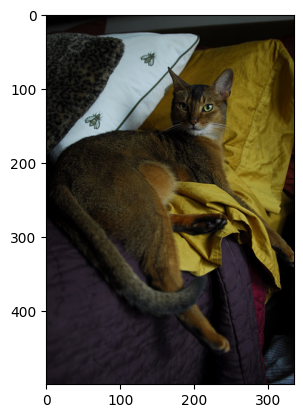

In [48]:
pilImg = Image.open(r'annotations/images/Abyssinian_14.jpg')
np_img = np.array(pilImg)
# np_img.shape
plt.imshow(np_img)

In [49]:
# 专门解析处理xlm文件的模块
from lxml import etree
xml = open(r'annotations/xmls/Abyssinian_14.xml').read()
xml

'<annotation><folder>OXIIIT</folder><filename>Abyssinian_14.jpg</filename><source><database>OXFORD-IIIT Pet Dataset</database><annotation>OXIIIT</annotation><image>flickr</image></source><size><width>335</width><height>500</height><depth>3</depth></size><segmented>0</segmented><object><name>cat</name><pose>Frontal</pose><truncated>0</truncated><occluded>0</occluded><bndbox><xmin>164</xmin><ymin>71</ymin><xmax>252</xmax><ymax>163</ymax></bndbox><difficult>0</difficult></object></annotation>\n'

In [50]:
doc = etree.HTML(xml)
width = int(doc.xpath('//size/width/text()')[0])
height = int(doc.xpath('//size/height/text()')[0])
depth = int(doc.xpath('//size/depth/text()')[0])
width,height,depth

(335, 500, 3)

In [51]:
# 获取头部四个点
xmin = int(doc.xpath('//bndbox/xmin/text()')[0])
xmax = int(doc.xpath('//bndbox/xmax/text()')[0])
ymin = int(doc.xpath('//bndbox/ymin/text()')[0])
ymax = int(doc.xpath('//bndbox/ymax/text()')[0])
xmin,xmax,ymin,ymax

(164, 252, 71, 163)

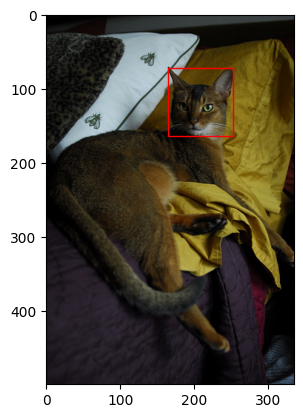

In [52]:
from matplotlib.patches import Rectangle
plt.imshow(np_img)
# 在图片上画矩形
rect = Rectangle((xmin,ymin),(xmax-xmin),(ymax-ymin),fill=False,color='red')
# 获取图像绘制位置
ax = plt.gca()
# 在图像上添加矩形
ax.axes.add_patch(rect)
plt.show()

In [53]:
import glob
# 创建输入
images = glob.glob(r'annotations/images/*.jpg')
images[:5]

['annotations/images\\Abyssinian_1.jpg',
 'annotations/images\\Abyssinian_10.jpg',
 'annotations/images\\Abyssinian_100.jpg',
 'annotations/images\\Abyssinian_101.jpg',
 'annotations/images\\Abyssinian_102.jpg']

In [54]:
len(images)

7390

In [55]:
# 获取所有xml文件路径
xmls = glob.glob('annotations/xmls/*.xml')
print(xmls[:5])
len(xmls)

['annotations/xmls\\Abyssinian_1.xml', 'annotations/xmls\\Abyssinian_10.xml', 'annotations/xmls\\Abyssinian_100.xml', 'annotations/xmls\\Abyssinian_101.xml', 'annotations/xmls\\Abyssinian_102.xml']


3686

In [56]:
xmls_names=[]
for x in xmls:
    x = x.split('\\')[-1]
    x = x.split('.xml')[0]
    xmls_names.append(x)
xmls_names[:5]

['Abyssinian_1',
 'Abyssinian_10',
 'Abyssinian_100',
 'Abyssinian_101',
 'Abyssinian_102']

In [57]:
imgs = []
imgNames = []
for img in images:
    imgName = img.split('\\')[-1]
    imgName = imgName.split('.jpg')[0]
    imgNames.append(imgName)
    if imgName in xmls_names:
        imgs.append(img)
imgs[:5]

    

['annotations/images\\Abyssinian_1.jpg',
 'annotations/images\\Abyssinian_10.jpg',
 'annotations/images\\Abyssinian_100.jpg',
 'annotations/images\\Abyssinian_101.jpg',
 'annotations/images\\Abyssinian_102.jpg']

In [58]:
def to_labels(path):
    xml = open(path).read()
    doc = etree.HTML(xml)
    width = int(doc.xpath('//size/width/text()')[0])
    height = int(doc.xpath('//size/height/text()')[0])
    depth = int(doc.xpath('//size/depth/text()')[0])
    
    xmin = int(doc.xpath('//bndbox/xmin/text()')[0])
    xmax = int(doc.xpath('//bndbox/xmax/text()')[0])
    ymin = int(doc.xpath('//bndbox/ymin/text()')[0])
    ymax = int(doc.xpath('//bndbox/ymax/text()')[0])

    return (xmin/width,ymin/height,xmax/width,ymax/height)

In [59]:
# 获取结果列表
labels = [ to_labels(path) for path in xmls]
labels[:5]

[(0.555, 0.18, 0.7083333333333334, 0.395),
 (0.192, 0.21, 0.768, 0.582),
 (0.383248730964467, 0.142, 0.850253807106599, 0.534),
 (0.12, 0.11501597444089456, 0.7088888888888889, 0.7507987220447284),
 (0.046, 0.05806451612903226, 0.65, 0.6881720430107527)]

In [60]:
# 随机我们的数据集
# 设置随机种子,方便复现
np.random.seed(2022)

# 生成一个从 0到你设置长度的随机数序列 【0,1,2,3,4,5,6,7,8,9】>>>【5,3,2,1,8,6,9,7,4,0】
index = np.random.permutation(len(imgs))
index[0:5]

array([1852,  189, 2779,  683, 1869], dtype=int32)

In [61]:
# 将索引值给到imgs和labels
images = np.array(imgs)[index]
labels = np.array(labels,np.float32)[index]
print(images[:5],labels[:5])

['annotations/images\\keeshond_157.jpg'
 'annotations/images\\american_bulldog_192.jpg'
 'annotations/images\\Russian_Blue_192.jpg'
 'annotations/images\\Birman_178.jpg'
 'annotations/images\\keeshond_172.jpg'] [[0.396      0.07466666 0.62       0.45066667]
 [0.134      0.30788177 0.474      0.8817734 ]
 [0.19760479 0.104      0.7994012  0.526     ]
 [0.09333333 0.266      0.29333332 0.416     ]
 [0.336      0.14414415 0.612      0.6186186 ]]


In [62]:
# 80%数据训练，20%测试
sep = int(len(imgs)*0.8)
train_images = images[:sep]
train_labels = labels[:sep]
test_images = images[sep:]
test_labels = labels[sep:]

In [63]:
# 编写转换函数
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

In [64]:
# 创建数据集对象
class Dataset(data.Dataset):
    def __init__(self,img_paths,labels,transform):
        self.imgs = img_paths
        self.labels = labels
        self.transforms = transform
    def __getitem__(self,index):
        # 拿到图片路径
        img = self.imgs[index]
        pil_img = Image.open(img)
        pil_img = pil_img.convert('RGB')
        pil_img = transform(pil_img)
        label = self.labels[index]
        return pil_img,label
    def __len__(self):
        return len(self.imgs)
    
    

In [65]:
train_dataset = Dataset(train_images,train_labels,transform)
test_dataset = Dataset(test_images,test_labels,transform)

In [66]:
BATCH_SIZE = 16
# 数据加载器
train_dl = torch.utils.data.DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    shuffle = True
)
test_dl = torch.utils.data.DataLoader(
    test_dataset,
    batch_size = BATCH_SIZE
)

In [67]:
# 创建定位模型
# 使用预训练好的resnet101模型
# resnet = torchvision.models.resnet101(pretrain = True)
resnet = torchvision.models.resnet101(weights=torchvision.models.ResNet101_Weights.IMAGENET1K_V1)


In [68]:
resnet

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [69]:
# 残差网络全连接层的输入
input_num = resnet.fc.in_features

In [70]:
list(resnet.children())[:-1]

[Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False),
 BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True),
 ReLU(inplace=True),
 MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False),
 Sequential(
   (0): Bottleneck(
     (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
     (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
     (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
     (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     (relu): ReLU(inplace=True)
     (downsample): Sequential(
       (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
       (1): BatchNorm2d(256, eps=1e-05, momentum

In [71]:
class Net(nn.Module):
    def __init__(self):
        super(Net,self).__init__()
        # 提取残差网络除了最后一层的所有网络
        self.resnet_base = nn.Sequential(*list(resnet.children())[:-1])
        self.fc = nn.Linear(input_num,4)
    def forward(self,x):
        x = self.resnet_base(x)
        x = x.view(x.size(0),-1)
        x = self.fc(x)
        return x

In [72]:
model = Net()

In [73]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = model.to(device)
device

'cuda'

In [74]:
# 定义损失函数
loss_fn = nn.MSELoss()
# 定义优化器
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)

In [75]:
def train(dataLoader,model,loss_fn,optimizer):
    num_batches = len(dataLoader)
    train_loss = 0
    model.train()
    # model.train()：开启随机丢弃神经元，随机屏蔽部分特征，防止过拟合；
    # model.eval()：关闭 Dropout，所有神经元全部参与计算。
    for X,Y in dataLoader:
        X,Y = X.to(device),Y.to(device)
        # 将输入给到模型，进行前向传播
        y_pred = model(X)
        # 拿到预测的值跟真实值对比，计算误差
        loss= loss_fn(y_pred,Y)
        # 梯度归零，反向传播，优化器跟新参数
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            train_loss += loss.item()
    train_loss /= num_batches
    return train_loss

In [76]:
def test(dataLoader,model):
    num_batches = len(dataLoader)
    # 用于测试，禁用掉BatchNorm 以及dropout
    model.eval()
    test_loss = 0
    with torch.no_grad():
        for X,Y in dataLoader:
            X,Y = X.to(device),Y.to(device)
            # 将输入给到模型，进行前向传播
            y_pred = model(X)
            # 拿到预测的值跟真实值对比，计算误差
            loss= loss_fn(y_pred,Y)
            test_loss += loss.item()
    test_loss /= num_batches
    return test_loss
        

In [77]:
def fit(epochs = 20):
    train_loss=[]
    test_loss=[]
    for epoch in range(epochs):
        epoch_train_loss = train(train_dl,model,loss_fn,optimizer)
        epoch_test_loss = test(test_dl,model)
        train_loss.append(epoch_train_loss)
        test_loss.append(epoch_test_loss)
        print('epoch_train_loss:',epoch_train_loss,'      epoch_test_loss:',epoch_test_loss)
fit()

epoch_train_loss: 0.04120291496903913       epoch_test_loss: 0.07874522774301945
epoch_train_loss: 0.021582213054234918       epoch_test_loss: 0.021928668596801607
epoch_train_loss: 0.017914876145486897       epoch_test_loss: 0.016006821300834417
epoch_train_loss: 0.010936725504595686       epoch_test_loss: 0.011354374699294567
epoch_train_loss: 0.007228655899195253       epoch_test_loss: 0.011359625882370042
epoch_train_loss: 0.006677157969239193       epoch_test_loss: 0.017079138137558673
epoch_train_loss: 0.011030934184688973       epoch_test_loss: 0.00999660768169672
epoch_train_loss: 0.006101487487604892       epoch_test_loss: 0.014243619912799368
epoch_train_loss: 0.0058776723548165846       epoch_test_loss: 0.007089580493444141
epoch_train_loss: 0.007291883395078617       epoch_test_loss: 0.026662404530067393
epoch_train_loss: 0.005941711349815533       epoch_test_loss: 0.0074047381306027475
epoch_train_loss: 0.004111353396689771       epoch_test_loss: 0.006339453884023935
epoch

In [83]:
# 1. 只创建一次迭代器（全局/循环外定义）
test_iter = iter(test_dl)

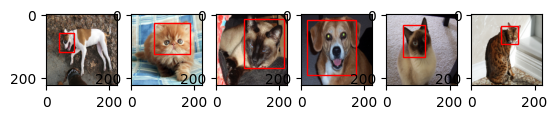

In [86]:
imgs,labels = next(test_iter)
imgs = imgs.to('cpu')
model = model.cpu()
out = model(imgs)
for i in range(6):
    plt.subplot(1,6,i+1)
    plt.imshow(imgs[i].permute(1,2,0).detach())
    xmin,ymin,xmax,ymax = tuple(out[i].detach().numpy()*224)
    # 在图像上画3矩形
    rect = Rectangle((xmin,ymin),(xmax-xmin),(ymax-ymin),fill = False,color='red')
    # 获取图像绘制区域
    ax =plt.gca()
    # 在图像上加矩形
    ax.axes.add_patch(rect)
    # 显示图像和矩形
plt.show()